## Лабораторная работа № 5
Самарин НА КИ25-04-3М

На основе Brazilian E-Commerce Public Dataset by Olist разработана модель классификации отзывов покупателей на положительные и отрицательные. Для обучения используются неструктурированные текстовые комментарии и структурированные характеристики заказов: оценка покупателя, стоимость товарных позиций и срок доставки.

Оценки 4–5 относятся к положительным отзывам, оценки 1–2 — к отрицательным. Нейтральные отзывы с оценкой 3 исключаются из обучения.

### 1. Инициализация

In [ ]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType
from pyspark.ml import Pipeline
from pyspark.ml.feature import RegexTokenizer, StopWordsRemover, CountVectorizer, IDF, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator
from pyspark.ml import PipelineModel
import matplotlib.pyplot as plt
import pandas as pd
import sys
import os

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
# os.environ["HADOOP_HOME"] = "C:\\hadoop"
# os.environ["hadoop.home.dir"] = "C:\\hadoop"
# os.environ["PATH"] += os.pathsep + "C:\\hadoop\\bin"

spark = (
    SparkSession.builder
    .appName("Olist_LR5_Spark_MLlib")
    .master("local[*]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.ui.enabled", "false")
    .config("spark.pyspark.python", sys.executable)
    .config("spark.pyspark.driver.python", sys.executable)
    .config("spark.python.worker.faulthandler.enabled", "true")
    .config("spark.sql.execution.pyspark.udf.faulthandler.enabled", "true")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

# Проверяем что spark работает
print("Spark version:", spark.version)
print("Master:", spark.sparkContext.master)
print("Application:", spark.sparkContext.appName)
print("Spark UI:", spark.sparkContext.uiWebUrl)
spark.range(3).show()

Spark version: 4.3.0
Master: local[*]
Application: Olist_LR5_Spark_MLlib
Spark UI: None
+---+
| id|
+---+
|  0|
|  1|
|  2|
+---+



### 2. Импорт очищенных данных

Используются очищенные Parquet-таблицы, подготовленные в ЛР 3.

In [4]:
DATA_DIR = "data"

PATHS = {
    "orders": f"{DATA_DIR}/orders_clean",
    "order_items": f"{DATA_DIR}/order_items_clean",
    "products": f"{DATA_DIR}/products_clean",
    "customers": f"{DATA_DIR}/customers_clean",
    "reviews": f"{DATA_DIR}/reviews_clean"
}

for name, path in PATHS.items():
    print(f"{name}: {path} | exists={os.path.exists(path)}")

orders = spark.read.parquet(PATHS["orders"])
order_items = spark.read.parquet(PATHS["order_items"])
products = spark.read.parquet(PATHS["products"])
customers = spark.read.parquet(PATHS["customers"])
reviews = spark.read.parquet(PATHS["reviews"])

for name, df in {
    "orders": orders,
    "order_items": order_items,
    "products": products,
    "customers": customers,
    "reviews": reviews
}.items():
    print(f"{name}: {df.count()} строк")
    print(df.columns)

orders: data/orders_clean | exists=True
order_items: data/order_items_clean | exists=True
products: data/products_clean | exists=True
customers: data/customers_clean | exists=True
reviews: data/reviews_clean | exists=True
orders: 99441 строк
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
order_items: 112650 строк
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
products: 32951 строк
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
customers: 99441 строк
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
reviews: 98410 строк
['review_id', 'order_id', 'review_score', 'review_comment_title', 'revi

### 3. Объединение структурированных и неструктурированных данных

In [5]:
# Проверка обязательных столбцов
required_reviews = {"order_id", "review_score", "review_comment_message"}
required_orders = {"order_id", "order_purchase_timestamp"}
required_items = {"order_id", "price"}

for label, df, required in [
    ("reviews", reviews, required_reviews),
    ("orders", orders, required_orders),
    ("order_items", order_items, required_items)
]:
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"В таблице {label} отсутствуют столбцы: {missing}")

# Агрегирование товарных позиций на уровне заказа
items_agg = (
    order_items
    .groupBy("order_id")
    .agg(
        F.sum("price").alias("order_value"),
        F.count("*").alias("items_count")
    )
)

# Выбираем доступные поля заказа
order_columns = ["order_id", "order_purchase_timestamp"]
if "order_delivered_customer_date" in orders.columns:
    order_columns.append("order_delivered_customer_date")

orders_selected = orders.select(*order_columns)

model_data = (
    reviews
    .select("order_id", "review_score", "review_comment_message")
    .join(orders_selected, on="order_id", how="left")
    .join(items_agg, on="order_id", how="left")
)

# Срок доставки в днях, если доступны обе даты
if "order_delivered_customer_date" in model_data.columns:
    model_data = model_data.withColumn(
        "delivery_days",
        F.when(
            F.col("order_delivered_customer_date").isNotNull()
            & F.col("order_purchase_timestamp").isNotNull(),
            (F.unix_timestamp("order_delivered_customer_date")
             - F.unix_timestamp("order_purchase_timestamp")) / 86400.0
        )
    )
else:
    model_data = model_data.withColumn("delivery_days", F.lit(None).cast("double"))

model_data = (
    model_data
    .withColumn("review_score", F.col("review_score").cast("double"))
    .withColumn("order_value", F.col("order_value").cast("double"))
    .withColumn("items_count", F.col("items_count").cast("double"))
    .withColumn("delivery_days", F.col("delivery_days").cast("double"))
)

print("Количество записей после объединения:", model_data.count())
model_data.select(
    "review_score", "review_comment_message",
    "order_value", "items_count", "delivery_days"
).show(10, truncate=80)

Количество записей после объединения: 98410
+------------+--------------------------------------------------------------------------------+-----------+-----------+------------------+
|review_score|                                                          review_comment_message|order_value|items_count|     delivery_days|
+------------+--------------------------------------------------------------------------------+-----------+-----------+------------------+
|         5.0|                                                                                |      145.0|        1.0| 26.85247685185185|
|         5.0|                                                                                |       13.5|        1.0|14.994965277777778|
|         5.0|                                                                                |       89.8|        1.0|10.007430555555555|
|         5.0|                  Chegou bem antes do prazo e o material de muito boa qualidade!|       55.0|        1.0| 6.

### 4. Подготовка целевой переменной и признаков

In [6]:
dataset = (
    model_data
    .filter(F.col("review_score").isin(1.0, 2.0, 4.0, 5.0))
    .filter(F.col("review_comment_message").isNotNull())
    .filter(F.length(F.trim("review_comment_message")) > 0)
    .withColumn(
        "label",
        F.when(F.col("review_score") >= 4, 1.0).otherwise(0.0)
    )
    .fillna({
        "order_value": 0.0,
        "items_count": 0.0,
        "delivery_days": 0.0
    })
    .filter(F.col("delivery_days").isNull() | (F.col("delivery_days") >= 0))
)

print("Количество отзывов для обучения:", dataset.count())
dataset.groupBy("label").count().show()
dataset.select(
    "review_score", "label", "order_value", "items_count", "delivery_days"
).show(10)

Количество отзывов для обучения: 37130
+-----+-----+
|label|count|
+-----+-----+
|  1.0|26371|
|  0.0|10759|
+-----+-----+

+------------+-----+-----------+-----------+------------------+
|review_score|label|order_value|items_count|     delivery_days|
+------------+-----+-----------+-----------+------------------+
|         5.0|  1.0|       55.0|        1.0| 6.814930555555556|
|         5.0|  1.0|      209.0|        1.0| 9.482210648148149|
|         2.0|  0.0|      169.9|        1.0|11.893587962962963|
|         5.0|  1.0|       84.9|        1.0|  8.74900462962963|
|         5.0|  1.0|       16.9|        1.0|3.9494212962962965|
|         5.0|  1.0|       36.9|        1.0| 20.24329861111111|
|         5.0|  1.0|     129.99|        1.0| 6.286851851851852|
|         5.0|  1.0|     139.94|        1.0|18.426076388888887|
|         5.0|  1.0|       49.9|        1.0|            1.9225|
|         5.0|  1.0|      44.99|        1.0| 4.978541666666667|
+------------+-----+-----------+-----------+

### 5. Разделение на обучающую и тестовую выборки

In [7]:
train_data, test_data = dataset.randomSplit([0.8, 0.2], seed=42)

print("Обучающая выборка:", train_data.count())
print("Тестовая выборка:", test_data.count())

print("Распределение классов в обучающей выборке:")
train_data.groupBy("label").count().show()

Обучающая выборка: 29853
Тестовая выборка: 7277
Распределение классов в обучающей выборке:
+-----+-----+
|label|count|
+-----+-----+
|  1.0|21229|
|  0.0| 8624|
+-----+-----+



### 6. Преобразование текстовых данных в числовые признаки

Используются следующие компоненты Spark ML:
- RegexTokenizer — разделение текста на слова;
- StopWordsRemover — удаление часто встречающихся служебных слов;
- CountVectorizer — построение вектора частот слов;
- IDF — снижение веса слов, которые часто встречаются во многих документах.

In [8]:
tokenizer = RegexTokenizer(
    inputCol="review_comment_message",
    outputCol="tokens",
    pattern="\\W+",
    minTokenLength=2,
    toLowercase=True
)

portuguese_stop_words = [
    "de", "a", "o", "que", "e", "do", "da", "em", "um", "uma",
    "para", "com", "não", "nao", "no", "por", "os", "as", " dos",
    "das", "ao", "mais", "muito", "foi", "ser", "se", "me", "eu",
    "como", "já", "ja", "mas", "ou", "sua", "seu"
]

remover = StopWordsRemover(
    inputCol="tokens",
    outputCol="filtered_tokens",
    stopWords=portuguese_stop_words
)

vectorizer = CountVectorizer(
    inputCol="filtered_tokens",
    outputCol="raw_features",
    vocabSize=5000,
    minDF=2
)

idf = IDF(
    inputCol="raw_features",
    outputCol="text_features"
)

print("Компоненты обработки текста подготовлены.")

Компоненты обработки текста подготовлены.


### 7. Формирование общего вектора признаков. Формирование ML Pipeline

К текстовым признакам добавляются структурированные характеристики заказа: стоимость товарных позиций, количество товаров и срок доставки. VectorAssembler объединяет их в единый вектор `features`.

In [9]:
assembler = VectorAssembler(
    inputCols=[
        "text_features",
        "order_value",
        "items_count",
        "delivery_days"
    ],
    outputCol="features",
    handleInvalid="keep"
)

lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    predictionCol="prediction",
    maxIter=30,
    regParam=0.01
)

pipeline = Pipeline(stages=[
    tokenizer,
    remover,
    vectorizer,
    idf,
    assembler,
    lr
])

print("ML Pipeline сформирован.")

ML Pipeline сформирован.


### 8. Обучение модели Logistic Regression

In [10]:
model = pipeline.fit(train_data)
print("Обучение модели завершено.")

Обучение модели завершено.


### 9. Получение предсказаний

In [11]:
predictions = model.transform(test_data)

predictions.select(
    "review_score",
    "label",
    "prediction",
    "probability"
).show(20, truncate=100)

+------------+-----+----------+------------------------------------------+
|review_score|label|prediction|                               probability|
+------------+-----+----------+------------------------------------------+
|         2.0|  0.0|       0.0| [0.9879525092659366,0.012047490734063415]|
|         5.0|  1.0|       1.0|  [0.03643357209783333,0.9635664279021666]|
|         1.0|  0.0|       0.0|  [0.8918210305467376,0.10817896945326244]|
|         1.0|  0.0|       0.0|   [0.6670627357485598,0.3329372642514402]|
|         5.0|  1.0|       1.0|  [0.20586494400464941,0.7941350559953506]|
|         5.0|  1.0|       1.0|  [0.03562752674741457,0.9643724732525855]|
|         5.0|  1.0|       1.0|  [0.03583035214252625,0.9641696478574737]|
|         5.0|  1.0|       1.0| [0.014546599694293692,0.9854534003057063]|
|         5.0|  1.0|       1.0|   [0.01961082148596404,0.980389178514036]|
|         2.0|  0.0|       0.0| [0.9927227084569316,0.007277291543068443]|
|         4.0|  1.0|     

### 10. Оценка качества модели

Для оценки используются метрики Accuracy, F1-score и Area Under ROC. 

In [12]:
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="accuracy"
)
f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="f1"
)
auc_evaluator = BinaryClassificationEvaluator(
    labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC"
)

accuracy = accuracy_evaluator.evaluate(predictions)
f1 = f1_evaluator.evaluate(predictions)
auc = auc_evaluator.evaluate(predictions)

print(f"Accuracy: {accuracy:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {auc:.4f}")

Accuracy: 0.9088
F1-score: 0.9074
ROC-AUC: 0.9485


### 11. Матрица ошибок и визуализация результатов

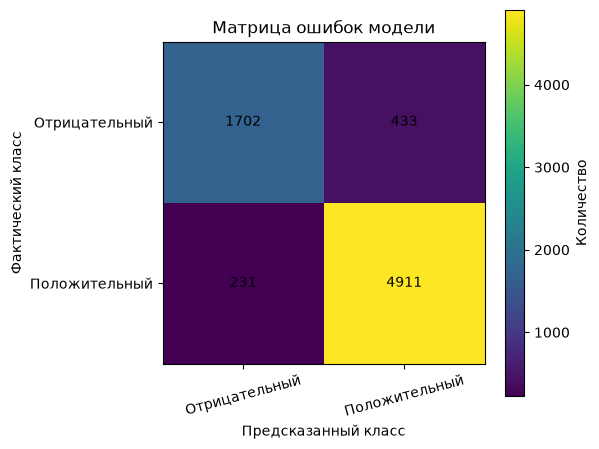

In [13]:
confusion = (
    predictions
    .groupBy("label", "prediction")
    .count()
    .toPandas()
)

matrix = [[0, 0], [0, 0]]
for _, row in confusion.iterrows():
    matrix[int(row["label"])][int(row["prediction"])] = int(row["count"])

plt.figure(figsize=(6, 5))
plt.imshow(matrix)
plt.title("Матрица ошибок модели")
plt.xlabel("Предсказанный класс")
plt.ylabel("Фактический класс")
plt.xticks([0, 1], ["Отрицательный", "Положительный"], rotation=15)
plt.yticks([0, 1], ["Отрицательный", "Положительный"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, matrix[i][j], ha="center", va="center")
plt.colorbar(label="Количество")
plt.tight_layout()
plt.show()

### 12. Анализ распределения предсказаний

+----------+-----+
|prediction|count|
+----------+-----+
|       0.0| 1933|
|       1.0| 5344|
+----------+-----+



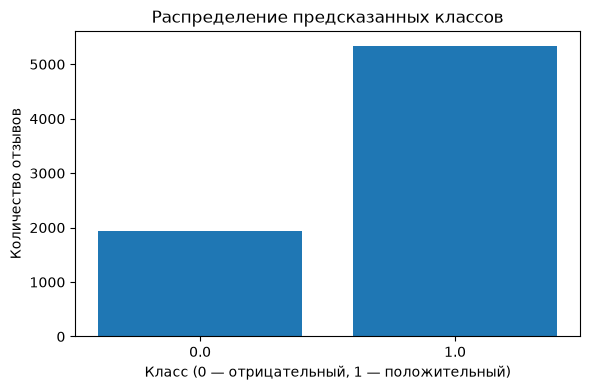

In [14]:
prediction_distribution = (
    predictions.groupBy("prediction").count().orderBy("prediction")
)
prediction_distribution.show()

distribution_pd = prediction_distribution.toPandas()
plt.figure(figsize=(6, 4))
plt.bar(
    distribution_pd["prediction"].astype(str),
    distribution_pd["count"]
)
plt.title("Распределение предсказанных классов")
plt.xlabel("Класс (0 — отрицательный, 1 — положительный)")
plt.ylabel("Количество отзывов")
plt.tight_layout()
plt.show()

### 13. Сохранение модели и результатов

Обученная модель сохраняется в формате Spark ML.

In [15]:
OUTPUT_DIR = "data/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

model_path = f"{OUTPUT_DIR}/sentiment_pipeline_model"
predictions_path = f"{OUTPUT_DIR}/test_predictions"
metrics_path = f"{OUTPUT_DIR}/metrics"

model.write().overwrite().save(model_path)

predictions.select(
    "order_id", "review_score", "label", "prediction", "probability"
).write.mode("overwrite").parquet(predictions_path)

metrics_df = spark.createDataFrame(
    [(float(accuracy), float(f1), float(auc))],
    ["accuracy", "f1_score", "roc_auc"]
)
metrics_df.write.mode("overwrite").option("header", True).csv(metrics_path)

print("Модель и результаты сохранены в", OUTPUT_DIR)

Модель и результаты сохранены в data/output


### 14. Сравнение ЛР 4 и ЛР 5

В ЛР 4 выполнялась аналитическая обработка данных: расчёт выручки, количества заказов, анализ категорий товаров, регионов и частоты слов в отзывах с использованием MapReduce. Эти методы описывают и агрегируют имеющиеся данные.

В ЛР 5 дополнительно построена модель машинного обучения, которая использует текст комментария и структурированные характеристики заказа для классификации отзыва. Качество модели оценивается на отложенной тестовой выборке с помощью Accuracy, F1-score и ROC-AUC.